# HPC log EDA

## Load data

In [1]:
import re
import pandas as pd

LOG_PATH = "HPC.log"
COLUMNS = ["event_id", "node", "component", "state", "time", "flag", "message"]

LINE_RE = re.compile(r"^(\d+) (.*?) (\S+) (\S+) (\d+(?:\.\d+)?) (-?\d)(?: (.*))?$")


def load_hpc_log(path=LOG_PATH):
    with open(path, "rb") as f:
        lines = [l for l in f.read().decode("ascii").split("\r\n") if l]

    rows, unparsed = [], []
    for line in lines:
        m = LINE_RE.match(line)
        if m:
            rows.append(m.groups())
        else:
            unparsed.append(line)
    
    df = pd.DataFrame(rows, columns=COLUMNS)
    df["message"] = df["message"].fillna("")
    df["event_id"] = df["event_id"].astype("int64")
    df["flag"] = df["flag"].astype("int8")
    t = pd.to_numeric(df["time"], errors="coerce")
    df["bad_time"] = ~df["time"].str.fullmatch(r"\d{10}")
    df["ts"] = pd.to_datetime(t.where(~df["bad_time"]), unit="s")
    df["time"] = t
    df["row"] = range(len(df))
    return df, unparsed

In [2]:
df, unparsed = load_hpc_log()
print(f"{len(df):,} rows, {len(unparsed)} unparsed, {df.bad_time.sum()} bad timestamps")
df.head()

433,490 rows, 0 unparsed, 9 bad timestamps


,LogId,Node,Component,State,Time,Flag,Content,bad_time,ts,row
0,460903,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:56:56,0
1,460919,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:01,1
2,460932,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:06,2
3,460949,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:12,3
4,460971,resourcemgmtdaeomon node-25,server,subsys,1.145552e+09,1,failed to configure resourcemgmt subsystem err...,False,2006-04-20 16:57:17,4


## Column distributions

In [21]:
for col in ["component", "state", "flag"]:
    print(df[col].value_counts())
    print(len(df[col].unique()), " unique values \n")

Component
switch_module        131600
node                 113275
gige                 100190
unix.hw               30086
action                28591
clusterfilesystem     15947
partition              7542
boot_cmd               3902
domain                 1458
shutdown_cmd            398
tserver                 362
install_cmd              57
server                   50
del_member_cmd           32
Name: count, dtype: int64
14  unique values 

State
temperature                     154930
error                           105572
status                           67348
start                            27818
net.niff.up                      23121
fan                              21774
clusterfilesystem.not_served      8152
clusterfilesystem.no_server       5126
bcast-error                       3718
state_change.unavailable          2969
state_change.available            2869
fdmn.full                         2599
new                               2108
success                           1741


C:\Users\user\AppData\Local\Temp\ipykernel_19284\263627088.py:7: FutureWarning: The behavior of DatetimeProperties.to_pydatetime is deprecated, in a future version this will return a Series containing python datetime objects instead of an ndarray. To retain the old behavior, call `np.array` on the result
  mdates.date2num(plot_df.loc[plot_df["Component"] == component, "ts"].dt.to_pydatetime())


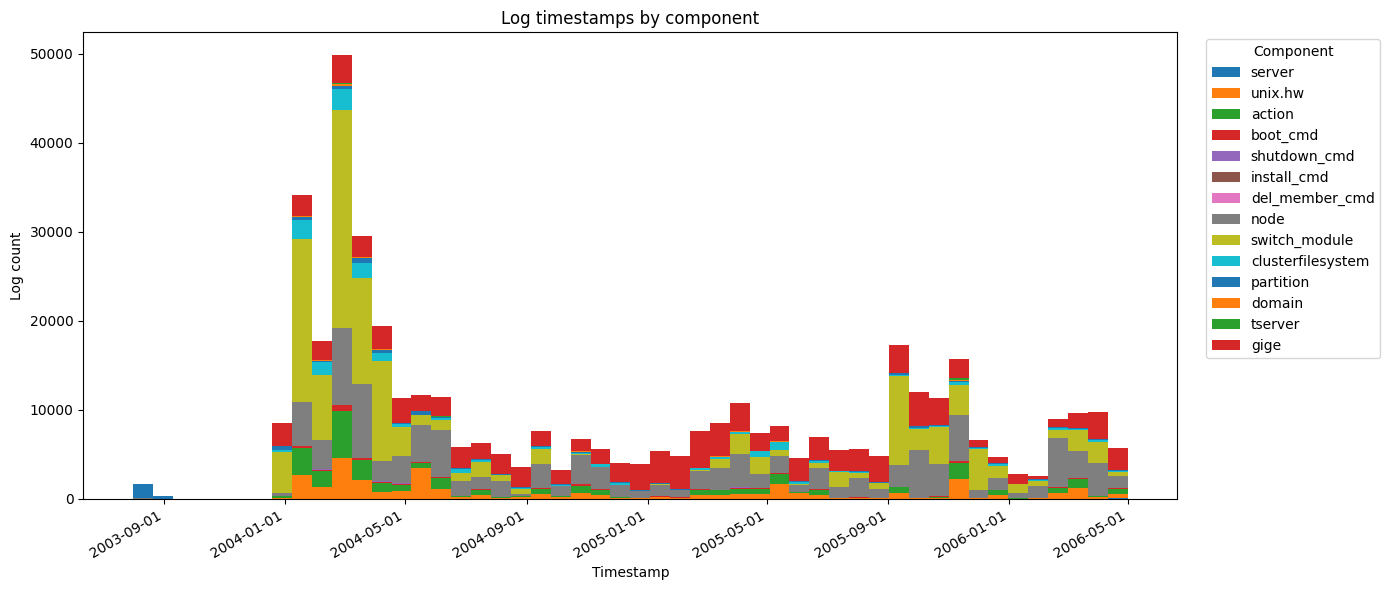

In [12]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plot_df = df.dropna(subset=["ts"])
components = plot_df["component"].unique()
times = [
    mdates.date2num(plot_df.loc[plot_df["component"] == component, "ts"].dt.to_pydatetime())
    for component in components
]

fig, ax = plt.subplots(figsize=(14, 6))
ax.hist(times, bins=50, stacked=True, label=components)
ax.xaxis_date()
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d"))
ax.set(xlabel="Timestamp", ylabel="Log count", title="Log timestamps by component")
ax.legend(title="component", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

## flag by component and state
Trying to understand when the -1 and 0 flags show up

In [16]:
t = df.groupby(["component", "state", "flag"]).size().unstack("flag", fill_value=0)
t[(t[0] > 0) | (t[-1] > 0)].sort_values(by=[-1, 0, 1], ascending=False).head(10)

Flag                         -1      0       1
Component     State                           
partition     status       2083     36    5423
node          status       1045  11516   45425
switch_module error          34    134  104423
              control         3      0     528
node          temperature     0     73   54669
domain        status          0     20    1438

## flag over time

In [5]:
pd.crosstab(df.ts.dt.to_period("Q"), df.flag)

Flag,-1,0,1
ts,,,
2003Q3,1932,0,0
2003Q4,0,0,3930
2004Q1,26,2484,135292
2004Q2,832,2981,52543
2004Q3,57,1362,23606
2004Q4,0,918,20523
2005Q1,0,154,33458
2005Q2,0,1416,29106
2005Q3,306,1028,37132


## message templates
Normalize the text to identify common error/message templates in the content of the logs.

In [24]:
def crude_template(s):
    s = re.sub(r"\\04[27].*?\\04[27]", "<Q>", s)
    s = re.sub(r"\b0x[0-9a-fA-F]+\b", "<HEX>", s)
    s = re.sub(r"\b(node|gige|Interconnect)-?[\w-]*\d\b", "<NODE>", s)
    s = re.sub(r"\d+", "<N>", s)
    return re.sub(r"\s+", " ", s).strip()


df["tmpl"] = df.message.map(crude_template)
df.groupby(["component", "state", "tmpl"]).size().sort_values(ascending=False).head(200)

Component      State        tmpl                                                                                                       
switch_module  error        Linkerror event interval expired                                                                               84894
node           temperature  ambient=<N>                                                                                                    54739
gige           temperature  warning                                                                                                        49741
                            normal                                                                                                         45818
node           status       running                                                                                                        25123
                                                                                                                                           